# 01 · Exploratory data analysis — Dunnhumby *The Complete Journey*

**Goal:** understand the real shopping data before building features, the offer simulator and uplift models for the Nectar offer engine.

Business framing used throughout: *household* = Nectar member, *coupon / campaign* = Nectar Prices offer, *retail discount* = member (loyalty-card) price, *basket* = a shopping trip.

Questions this notebook answers:
1. What is in the data, and how clean is it?
2. Which time window is safe to model on?
3. How concentrated is customer value?
4. How do members shop (frequency, basket size, discount reliance)?
5. How were the real campaigns targeted — and can we estimate offer uplift from them directly?

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from nectar.config import WAREHOUSE_PATH
from nectar import viz
from nectar.viz import BLUE, ORANGE, GREY, TEXT_2

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
con = duckdb.connect(str(WAREHOUSE_PATH), read_only=True)

q = lambda sql: con.sql(sql).df()

## 1. What is in the data

In [2]:
tables = ["transactions", "products", "households", "campaigns", "campaign_members",
          "coupons", "coupon_redemptions", "promotions"]
pd.DataFrame({
    "table": tables,
    "rows": [con.execute(f"SELECT COUNT(*) FROM raw.{t}").fetchone()[0] for t in tables],
}).style.format({"rows": "{:,}"}).hide(axis="index")

table,rows
transactions,"2,595,732"
products,"92,353"
households,801
campaigns,30
campaign_members,"7,208"
coupons,"124,548"
coupon_redemptions,"2,318"
promotions,"36,786,524"


In [3]:
q('''
SELECT COUNT(DISTINCT household_id)              AS members,
       COUNT(DISTINCT basket_id)                 AS baskets,
       COUNT(DISTINCT product_id)                AS products_bought,
       COUNT(DISTINCT store_id)                  AS stores,
       MAX(day)                                  AS days_covered,
       ROUND(SUM(sales_value))                   AS total_sales,
       ROUND(-SUM(retail_disc))                  AS member_price_discount,
       ROUND(-SUM(coupon_disc))                  AS coupon_discount
FROM raw.transactions
''')

,members,baskets,products_bought,stores,days_covered,total_sales,member_price_discount,coupon_discount
0,2500,276484,92339,582,711,"8,057,463.00","1,398,335.00","42,612.00"


### Data quirks found

- **Fuel and misc lines.** `KIOSK-GAS` and `MISC SALES TRAN` lines carry quantities up to ~90,000 (gallons / odometer-style values), not units. They are excluded from unit and basket analysis.
- **Zero-value lines.** About 18.9k lines have `sales_value <= 0` and ~14.5k have `quantity = 0` (returns, voids, free items).
- **A few positive discounts** (36 lines) — kept but tested so they stay rare.
- **Demographics cover only 801 of 2,500 members (32%)** and are anonymised in this copy (`age_group = "Age Group4"`, etc.).

The cell below defines the cleaned `grocery_lines` view used for the rest of the analysis.

In [4]:
con.execute('''
CREATE OR REPLACE TEMP VIEW grocery_lines AS
SELECT t.*, p.department, p.commodity, p.brand_type
FROM raw.transactions t JOIN raw.products p USING (product_id)
WHERE p.department NOT IN ('KIOSK-GAS', 'MISC SALES TRAN')
  AND t.quantity > 0 AND t.sales_value > 0
''')
q('''
SELECT (SELECT COUNT(*) FROM raw.transactions) AS all_lines,
       COUNT(*)                                 AS grocery_lines,
       1 - COUNT(*) / (SELECT COUNT(*) FROM raw.transactions) AS share_removed
FROM grocery_lines
''')

,all_lines,grocery_lines,share_removed
0,2595732,2548770,0.02


## 2. Which time window is safe to model on

The panel does not start full: members are recruited over the first few months. Modelling windows that include this ramp-up would confuse *new to the panel* with *low spender*.

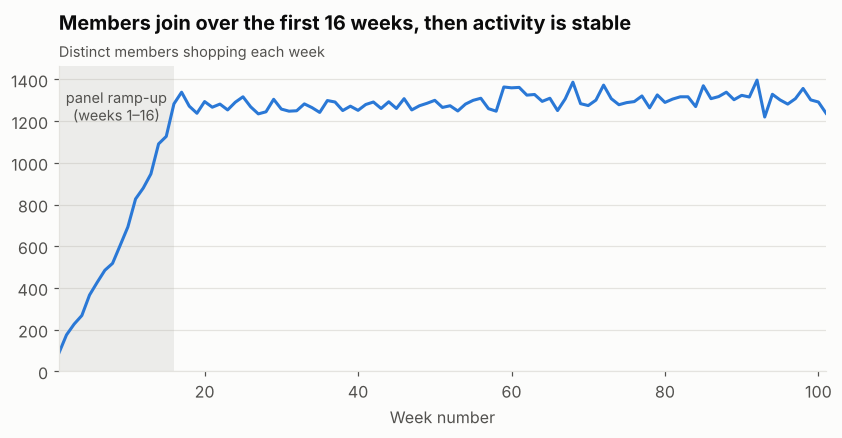

In [5]:
wk = q('''
SELECT week_no, COUNT(DISTINCT household_id) AS active_members, SUM(sales_value) AS sales
FROM grocery_lines GROUP BY 1 ORDER BY 1
''')
wk = wk[wk.week_no < wk.week_no.max()]  # final week is partial

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(wk.week_no, wk.active_members, color=BLUE)
ax.axvspan(1, 16, color=GREY, alpha=0.18, lw=0)
ax.text(8.5, wk.active_members.max() * 0.97, "panel ramp-up\n(weeks 1–16)", ha="center", va="top",
        color=TEXT_2, fontsize=9.5)
ax.set_title("Members join over the first 16 weeks, then activity is stable")
viz.subtitle(ax, "Distinct members shopping each week")
ax.set_xlabel("Week number")
ax.set_ylim(0)
ax.set_xlim(1, wk.week_no.max())
viz.save(fig, "01_weekly_active_members"); fig

In [6]:
steady = wk[wk.week_no >= 17]
print(f"Weeks 17+: {steady.active_members.mean():,.0f} active members/week on average "
      f"(min {steady.active_members.min():,}, max {steady.active_members.max():,})")

Weeks 17+: 1,293 active members/week on average (min 1,220, max 1,397)


**Decision:** feature and outcome windows start at week 17 (day 113) or later.

## 3. How concentrated is customer value

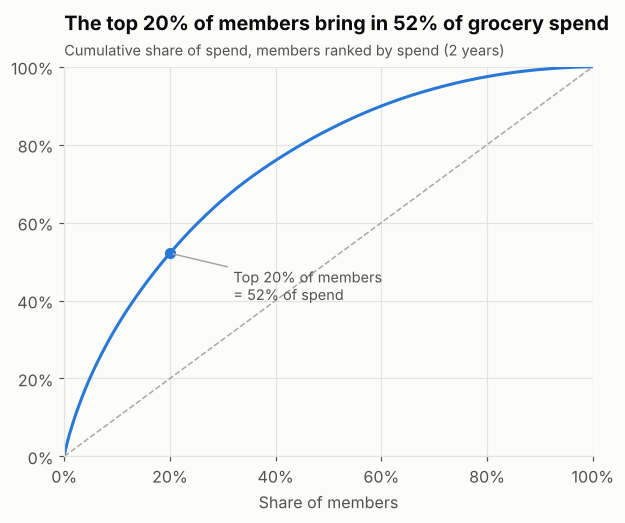

In [7]:
hh = q('''
SELECT household_id, SUM(sales_value) AS spend, COUNT(DISTINCT basket_id) AS trips
FROM grocery_lines GROUP BY 1
''').sort_values("spend", ascending=False).reset_index(drop=True)

hh["cum_share_members"] = (np.arange(len(hh)) + 1) / len(hh)
hh["cum_share_spend"] = hh.spend.cumsum() / hh.spend.sum()
top20 = hh.loc[hh.cum_share_members <= 0.2, "cum_share_spend"].max()
top50 = hh.loc[hh.cum_share_members <= 0.5, "cum_share_spend"].max()

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot(hh.cum_share_members, hh.cum_share_spend, color=BLUE)
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--")
ax.scatter([0.2], [top20], s=40, color=BLUE, zorder=3)
ax.annotate(f"Top 20% of members\n= {top20:.0%} of spend", (0.2, top20), xytext=(0.32, top20 - 0.12),
            color=TEXT_2, fontsize=9.5, arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_title(f"The top 20% of members bring in {top20:.0%} of grocery spend")
viz.subtitle(ax, "Cumulative share of spend, members ranked by spend (2 years)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Share of members"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.0)
ax.grid(axis="x")
viz.save(fig, "02_spend_concentration"); fig

In [8]:
print(f"Top 20% of members: {top20:.1%} of spend | top 50%: {top50:.1%}")
hh[["spend", "trips"]].describe(percentiles=[.1, .25, .5, .75, .9]).T

Top 20% of members: 52.1% of spend | top 50%: 83.8%


,count,mean,std,min,10%,25%,50%,75%,90%,max
spend,"2,500.00","2,957.30","2,970.50",8.17,360.44,916.11,"2,042.25","4,024.26","6,660.31","26,285.33"
trips,"2,500.00",100.45,104.76,1.00,18.00,36.00,73.00,129.00,210.10,"1,223.00"


## 4. How members shop

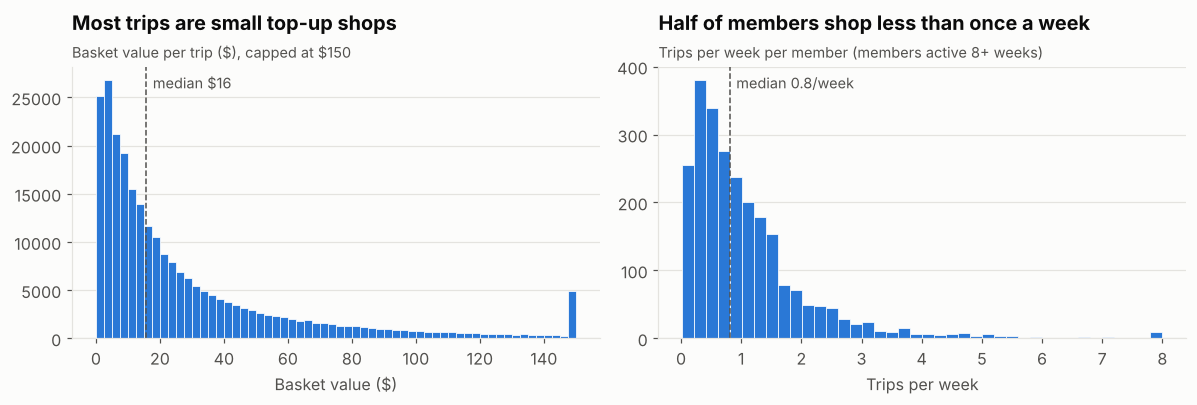

In [9]:
baskets = q('''
SELECT basket_id, household_id, SUM(sales_value) AS basket_value, SUM(quantity) AS items
FROM grocery_lines GROUP BY 1, 2
''')
freq = q('''
SELECT household_id, COUNT(DISTINCT basket_id) / ((MAX(day) - MIN(day) + 1) / 7.0) AS trips_per_week
FROM grocery_lines GROUP BY 1 HAVING MAX(day) - MIN(day) >= 56
''')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.hist(baskets.basket_value.clip(upper=150), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
med = baskets.basket_value.median()
ax.axvline(med, color=TEXT_2, lw=1, ls="--")
ax.text(med + 2, ax.get_ylim()[1] * 0.92, f"median ${med:.0f}", color=TEXT_2, fontsize=9.5)
ax.set_title("Most trips are small top-up shops")
viz.subtitle(ax, "Basket value per trip ($), capped at $150")
ax.set_xlabel("Basket value ($)")

ax = axes[1]
ax.hist(freq.trips_per_week.clip(upper=8), bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
medf = freq.trips_per_week.median()
ax.axvline(medf, color=TEXT_2, lw=1, ls="--")
ax.text(medf + 0.1, ax.get_ylim()[1] * 0.92, f"median {medf:.1f}/week", color=TEXT_2, fontsize=9.5)
ax.set_title("Half of members shop less than once a week")
viz.subtitle(ax, "Trips per week per member (members active 8+ weeks)")
ax.set_xlabel("Trips per week")
fig.tight_layout()
viz.save(fig, "03_basket_and_frequency"); fig

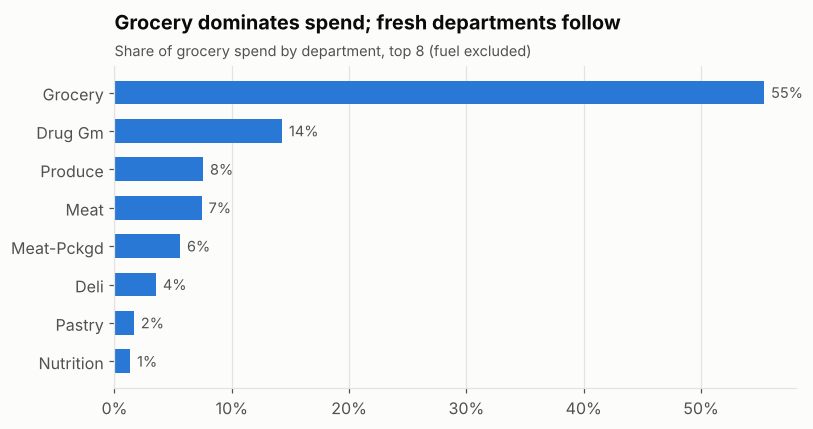

In [10]:
dept = q('''
SELECT department, SUM(sales_value) AS sales FROM grocery_lines GROUP BY 1 ORDER BY 2 DESC
''')
dept["share"] = dept.sales / dept.sales.sum()
top = dept.head(8).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(top.department.str.title(), top.share, color=BLUE, height=0.62)
for y, v in enumerate(top.share):
    ax.text(v + 0.006, y, f"{v:.0%}", va="center", color=TEXT_2, fontsize=9.5)
ax.set_title("Grocery dominates spend; fresh departments follow")
viz.subtitle(ax, "Share of grocery spend by department, top 8 (fuel excluded)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False); ax.grid(axis="x")
viz.save(fig, "04_department_share"); fig

### Member-price reliance (the Nectar Prices analogue)

`retail_disc` is the loyalty-card discount — the closest analogue to **Nectar Prices**. How much members depend on it is a strong candidate feature for price sensitivity.

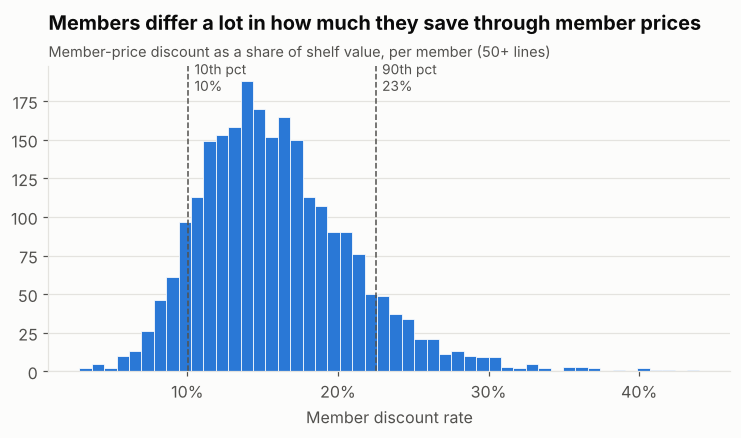

In [11]:
disc = q('''
SELECT household_id,
       -SUM(retail_disc) / SUM(sales_value - retail_disc) AS member_discount_rate,
       AVG((retail_disc < 0)::INT)                         AS share_lines_discounted
FROM grocery_lines GROUP BY 1 HAVING COUNT(*) >= 50
''')
overall = q('''SELECT -SUM(retail_disc) / SUM(sales_value - retail_disc) AS r,
                      AVG((retail_disc < 0)::INT) AS l FROM grocery_lines''').iloc[0]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(disc.member_discount_rate, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
p10, p90 = disc.member_discount_rate.quantile([.1, .9])
for v, lab in [(p10, "10th pct"), (p90, "90th pct")]:
    ax.axvline(v, color=TEXT_2, lw=1, ls="--")
    ax.text(v + 0.004, ax.get_ylim()[1] * 0.92, f"{lab}\n{v:.0%}", color=TEXT_2, fontsize=9)
ax.set_title("Members differ a lot in how much they save through member prices")
viz.subtitle(ax, "Member-price discount as a share of shelf value, per member (50+ lines)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Member discount rate")
viz.save(fig, "05_member_discount_rate"); fig

In [12]:
print(f"Across all grocery lines: {overall.l:.0%} of lines carry a member discount, "
      f"worth {overall.r:.1%} of shelf value.")
print(f"Per member, the discount rate ranges from {p10:.0%} (10th pct) to {p90:.0%} (90th pct).")

Across all grocery lines: 50% of lines carry a member discount, worth 15.6% of shelf value.
Per member, the discount rate ranges from 10% (10th pct) to 23% (90th pct).


## 5. How the real campaigns were targeted

In [13]:
camp = q('''
SELECT m.campaign_type,
       COUNT(DISTINCT m.household_id)                                  AS members_targeted,
       COUNT(*)                                                        AS member_campaigns,
       COUNT(DISTINCT CASE WHEN r.household_id IS NOT NULL
             THEN m.household_id || '-' || m.campaign_id END)         AS member_campaigns_redeemed
FROM raw.campaign_members m
LEFT JOIN (SELECT DISTINCT household_id, campaign_id FROM raw.coupon_redemptions) r
  USING (household_id, campaign_id)
GROUP BY 1 ORDER BY 1
''')
camp["redemption_rate"] = camp.member_campaigns_redeemed / camp.member_campaigns
camp

,campaign_type,members_targeted,member_campaigns,member_campaigns_redeemed,redemption_rate
0,TypeA,1513,3979,635,0.16
1,TypeB,1023,2655,210,0.08
2,TypeC,397,574,44,0.08


In [14]:
first_campaign_day = con.execute("SELECT MIN(start_day) FROM raw.campaigns").fetchone()[0]
print("First campaign starts on day", first_campaign_day)

First campaign starts on day 224


**The key test.** If campaigns had been sent at random, targeted and non-targeted members would have spent about the same *before* any campaign started. We compare weekly spend in the clean pre-campaign window (day 113 to day 223: after ramp-up, before the first campaign).

In [15]:
pre = q('''
WITH targeted AS (SELECT DISTINCT household_id FROM raw.campaign_members),
pre AS (
    SELECT household_id, SUM(sales_value) / 16.0 AS weekly_spend
    FROM grocery_lines WHERE day BETWEEN 113 AND 223 GROUP BY 1
)
SELECT pre.*, (t.household_id IS NOT NULL) AS targeted
FROM pre LEFT JOIN targeted t USING (household_id)
''')
summary = pre.groupby("targeted").weekly_spend.agg(["count", "median", "mean"])
summary

,count,median,mean
targeted,,,
False,788,6.51,10.75
True,1557,31.26,41.50


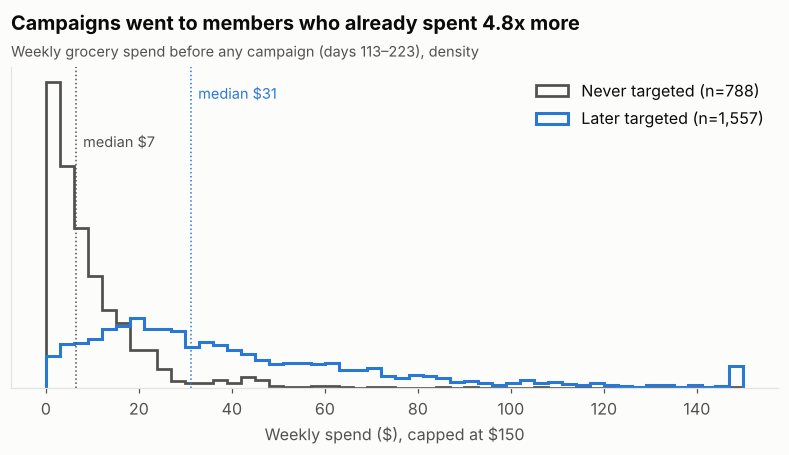

In [16]:
ratio = summary.loc[True, "median"] / summary.loc[False, "median"]
bins = np.linspace(0, 150, 51)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(pre.loc[~pre.targeted, "weekly_spend"].clip(upper=150), bins=bins, color=TEXT_2, histtype="step", linewidth=1.8,
        label=f"Never targeted (n={summary.loc[False,'count']:,})", density=True)
ax.hist(pre.loc[pre.targeted, "weekly_spend"].clip(upper=150), bins=bins, color=BLUE, histtype="step", linewidth=2,
        label=f"Later targeted (n={summary.loc[True,'count']:,})", density=True)
for flag, col in [(False, TEXT_2), (True, BLUE)]:
    m = summary.loc[flag, "median"]
    ax.axvline(m, color=col, lw=1, ls=":")
    ax.text(m + 1.5, ax.get_ylim()[1] * (0.9 if flag else 0.75), f"median ${m:.0f}", color=col, fontsize=9.5)
ax.set_title(f"Campaigns went to members who already spent {ratio:.1f}x more")
viz.subtitle(ax, "Weekly grocery spend before any campaign (days 113–223), density")
ax.set_xlabel("Weekly spend ($), capped at $150")
ax.set_yticks([])
ax.legend(loc="upper right")
viz.save(fig, "06_campaign_selection_bias"); fig

**Implication.** Targeting was strongly non-random: the retailer sent campaigns to its heavier shoppers. Comparing redeemers with non-redeemers (or targeted with non-targeted) would mostly measure *who was chosen*, not *what the offer caused*. This is why the project adds a **randomised offer simulator** on top of the real members: random assignment removes selection bias, and a known ground-truth uplift lets us check that the models recover it.

## 6. Demographics coverage

In [17]:
q('''
SELECT COUNT(*) AS members_with_demographics,
       COUNT(*) / 2500.0 AS share_of_members,
       AVG((household_id IN (SELECT household_id FROM raw.campaign_members))::INT) AS share_targeted
FROM raw.households
''')

,members_with_demographics,share_of_members,share_targeted
0,801,0.32,0.95


In [18]:
q("SELECT household_size, COUNT(*) AS members FROM raw.households GROUP BY 1 ORDER BY 1")

,household_size,members
0,1,255
1,2,318
2,3,109
3,4,53
4,5+,66


Demographics exist for a third of members, are anonymised, and 95% of those members were in a campaign (versus 63% overall), so the demographic subset is itself skewed. Therefore the core model is built on **behavioural features** (available for every member). Demographics are used only for fairness checks on the subset where they exist.

## Summary of findings

| # | Finding | What it means for the build |
|---|---|---|
| 1 | Members join over weeks 1–16 | Feature and outcome windows start at week 17 |
| 2 | Fuel / misc lines have non-unit quantities | Excluded via the `grocery_lines` view |
| 3 | Top 20% of members drive about half of spend | Report uplift in money terms and by value segment, not just per member |
| 4 | Typical member: ~1 trip a week, small top-up baskets | Frequency and recency are core features |
| 5 | Member-price reliance varies widely between members | Strong candidate driver of offer response in the simulator |
| 6 | Real campaigns targeted heavier spenders | Uplift can't be estimated cleanly from history: build the randomised simulator |
| 7 | Demographics for 32% only, anonymised, skewed to targeted members | Behavioural features for the model; demographics for fairness checks |

**Next (week 2):** dbt staging and mart models (`dim_member`, `fct_basket`, `fct_line`) with tests, then RFM segmentation.